# ECG EDA – MIT-BIH Arrhythmia Database
Verifies record integrity, AAMI class distribution per record, and why an inter-patient split is required.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
import wfdb, glob, collections
from ml.ecg.beat_dataset import AAMI_MAP, DS1, DS2, PACED
recs=sorted(os.path.basename(f)[:-4] for f in glob.glob('../datasets/mitdb/*.hea')); len(recs)

48

In [2]:
rows=[]
for r in recs:
    a=wfdb.rdann(f'../datasets/mitdb/{r}','atr'); c=collections.Counter(AAMI_MAP.get(s) for s in a.symbol if s in AAMI_MAP)
    rows.append({'record':r,'split':'DS1' if r in DS1 else 'DS2' if r in DS2 else 'paced', **c})
counts=pd.DataFrame(rows).fillna(0).set_index('record'); counts.groupby('split').sum()

,N,S,V,Q,F
split,,,,,
DS1,45868.0,942.0,3787.0,8.0,415.0
DS2,44258.0,1837.0,3221.0,7.0,388.0
paced,506.0,0.0,227.0,8028.0,0.0


In [3]:
counts[['S','V','F']].sort_values('F',ascending=False).head(10)

,S,V,F
record,,,
208,2.0,992.0,373.0
213,28.0,220.0,362.0
223,73.0,473.0,14.0
205,3.0,71.0,11.0
233,7.0,831.0,11.0
210,22.0,195.0,10.0
124,31.0,47.0,5.0
114,12.0,43.0,4.0
201,128.0,198.0,2.0


F beats are concentrated in a handful of records (e.g. 208 in DS1, 213 in DS2). A random beat-level split would put beats from the same patient in train and test and overstate performance – the Kaggle CSV split has this problem because it carries no record IDs.

Text(0.5, 0, 's')

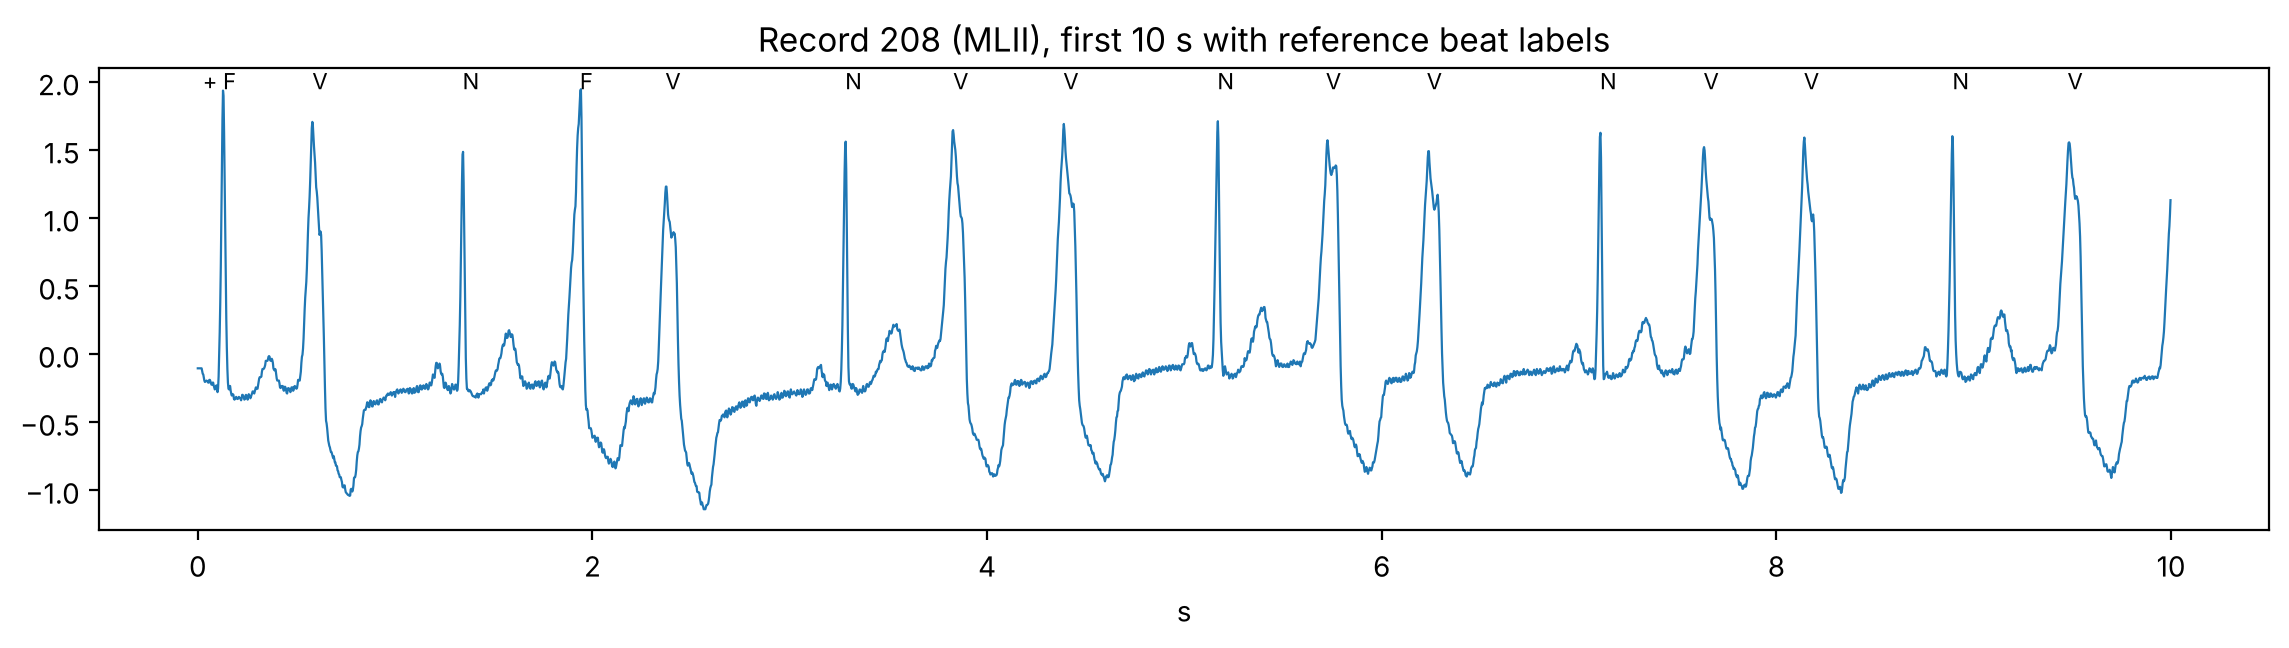

In [4]:
rec=wfdb.rdrecord('../datasets/mitdb/208',sampto=360*10); ann=wfdb.rdann('../datasets/mitdb/208','atr',sampto=360*10)
plt.figure(figsize=(14,3)); plt.plot(np.arange(rec.sig_len)/360, rec.p_signal[:,0],lw=.8)
for s,sym in zip(ann.sample,ann.symbol): plt.text(s/360, rec.p_signal[:,0].max(), sym, fontsize=8)
plt.title('Record 208 (MLII), first 10 s with reference beat labels'); plt.xlabel('s')

In [5]:
from ml.ecg.signal_processing import clean_ecg, signal_quality, detect_r_peaks
x=wfdb.rdrecord('../datasets/mitdb/105').p_signal[:360*60,0]
signal_quality(clean_ecg(x,360,60),360)  # record 105 is known to be noisy

{'kSQI': 13.411923549328304,
 'pSQI': 0.9227141605711001,
 'basSQI': 0.9944653304796892,
 'flatline_fraction': 0.0007870734756238715,
 'clipping_fraction': 0.0001388888888888889,
 'n_beats': 83,
 'heart_rate_bpm': 82.91746641074856,
 'checks': {'kurtosis_ok': True,
  'qrs_power_ok': False,
  'baseline_ok': True,
  'not_flat': True,
  'not_clipped': True,
  'hr_plausible': True},
 'score': 0.8333333333333334,
 'usable': True,
 'label': 'acceptable'}